In [1]:
from typing import Literal

from langchain.chat_models import init_chat_model
from langchain.tools import tool
from langchain_core.messages import HumanMessage, SystemMessage, ToolMessage
from langgraph.constants import START, END
from langgraph.graph import StateGraph, MessagesState
from dotenv import load_dotenv
load_dotenv()

True

In [2]:
# ====== Step 1: 准备工具 ======
# 工具
@tool
def get_weather(city: str) -> str:
    """获取城市天气"""
    weather_data = {
        "北京": "晴天 25度",
        "上海": "多云 28度",
        "杭州": "小雨 22度",
    }
    return weather_data.get(city, f"未找到{city}的天气信息")

@tool
def square_root(x: float) -> str:
    """Calculate the square root of a number"""
    return x ** 0.5

# 组成工具数组
tools = [get_weather, square_root]
# 组成工具名和工具的映射，方便查找工具
tools_by_name = {t.name: t for t in tools}

In [5]:
# ====== Step 2: 准备Model ======
# 定义模型
model = init_chat_model(
    'deepseek-v4-flash',
    extra_body = {'thinking': {'type': 'disabled'}}
)
# 绑定工具到模型
model_with_tools = model.bind_tools(tools)

In [15]:
# ====== Step 3: 准备节点 ======

def tool_node(state: MessagesState):
    # 获取最后一条消息，也就是AI返回的带工具的消息
    message = state['messages'][-1]
    messages=[]
    # 获取工具, 逐个处理
    for tool_call in message.tool_calls:
        # 获取工具信息
        _name = tool_call['name']
        _args = tool_call['args']
        _id = tool_call['id']
        # 调用工具
        result = tools_by_name[_name].invoke(_args)
        # 封装ToolMessage
        messages.append(ToolMessage(content=result, tool_call_id = _id))
    # 返回结果
    return {'messages': messages}

def llm_node(state: MessagesState):
    """LLM节点：调用模型，可以选择调用工具"""
    response = model_with_tools.invoke(state["messages"])
    return {"messages": [response]}

# 要定义路由，就是看AI返回消息中是否带有tool_call，有就走tool_node，没有就走END
def should_continue(state: MessagesState) -> Literal["tools", END]:
    """路由函数：判断下一步是继续调工具还是结束"""
    last_message = state["messages"][-1]
    # 如果包含tool_calls，则跳转到tools节点，没有则跳转到END节点
    if hasattr(last_message, 'tool_calls') and last_message.tool_calls:
        return "tools"  # 有工具调用 -> 去工具节点，调用工具
    return END # 没有有工具调用 -> 去END，直接返回AI消息给用户

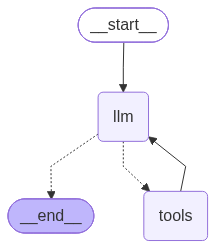

In [16]:
from IPython.core.display import Image

# 4.创建Graph
builder = StateGraph(MessagesState)

builder.add_node("llm", llm_node)
builder.add_node("tools", tool_node)

builder.add_edge(START, "llm")
builder.add_conditional_edges("llm", should_continue)
builder.add_edge("tools", "llm")

graph = builder.compile()


display(Image(graph.get_graph(xray=True).draw_mermaid_png()))

In [17]:
response = graph.invoke({"messages": [HumanMessage("杭州和北京天气怎样？")]})

for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

杭州和北京天气怎样？
================================== Ai Message ==================================
Tool Calls:
  get_weather (call_00_32A8ChKhvJXrNOR1RqM37334)
 Call ID: call_00_32A8ChKhvJXrNOR1RqM37334
  Args:
    city: 杭州
  get_weather (call_01_OhMi1LQF4p6GVHdQnPAc1424)
 Call ID: call_01_OhMi1LQF4p6GVHdQnPAc1424
  Args:
    city: 北京
================================= Tool Message =================================

小雨 22度
================================= Tool Message =================================

晴天 25度
================================== Ai Message ==================================

根据最新天气信息：

- **杭州**：小雨，气温 **22°C**。出门记得带伞哦 ☔
- **北京**：晴天，气温 **25°C**。天气不错，适合外出活动 ☀️

两地的温度都比较舒适，但杭州有小雨，出行注意防雨。还有什么需要帮忙的吗？
